# Currency risk: euro foreign-exchange reference rates, 1999-2021
European Central Bank daily reference rates for 40 currencies. The analysis measures **volatility regimes, correlations and tail risk**, and the value-at-risk of a sample multi-currency receivables book, the kind of FX exposure a CFO or treasurer manages.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
raw = pd.read_csv("data/ecb_euro_rates.csv")
raw = raw.rename(columns={raw.columns[0]: "date"}).set_index("date")
raw.index = pd.to_datetime(raw.index)
raw.columns = [c.strip("[] ").replace(" ]", "") for c in raw.columns]
fx = raw.apply(pd.to_numeric, errors="coerce").sort_index()          # "-" marks non-publication days
fx = fx.loc[:, fx.notna().mean() > 0.9]
print(f"{fx.shape[1]} currencies with >90% coverage, {fx.index.min():%Y-%m-%d} -> {fx.index.max():%Y-%m-%d}")
majors = ["US dollar", "UK pound sterling", "Japanese yen", "Swiss franc", "Chinese yuan renminbi", "Canadian dollar", "Australian dollar"]
majors = [c for c in majors if c in fx.columns]
r = np.log(fx[majors]).diff().dropna(how="all")
pd.DataFrame({"ann. vol": r.std() * np.sqrt(255), "worst day": r.min(), "best day": r.max(), "kurtosis": r.kurt()}).round(3)

31 currencies with >90% coverage, 1999-01-04 -> 2021-01-08


,ann. vol,worst day,best day,kurtosis
US dollar,0.097,-0.047,0.042,2.993
UK pound sterling,0.081,-0.030,0.053,5.167
Japanese yen,0.117,-0.061,0.054,4.796
Swiss franc,0.066,-0.156,0.080,396.230
Chinese yuan renminbi,0.095,-0.045,0.042,3.146
Canadian dollar,0.100,-0.039,0.045,2.611
Australian dollar,0.106,-0.064,0.064,6.885


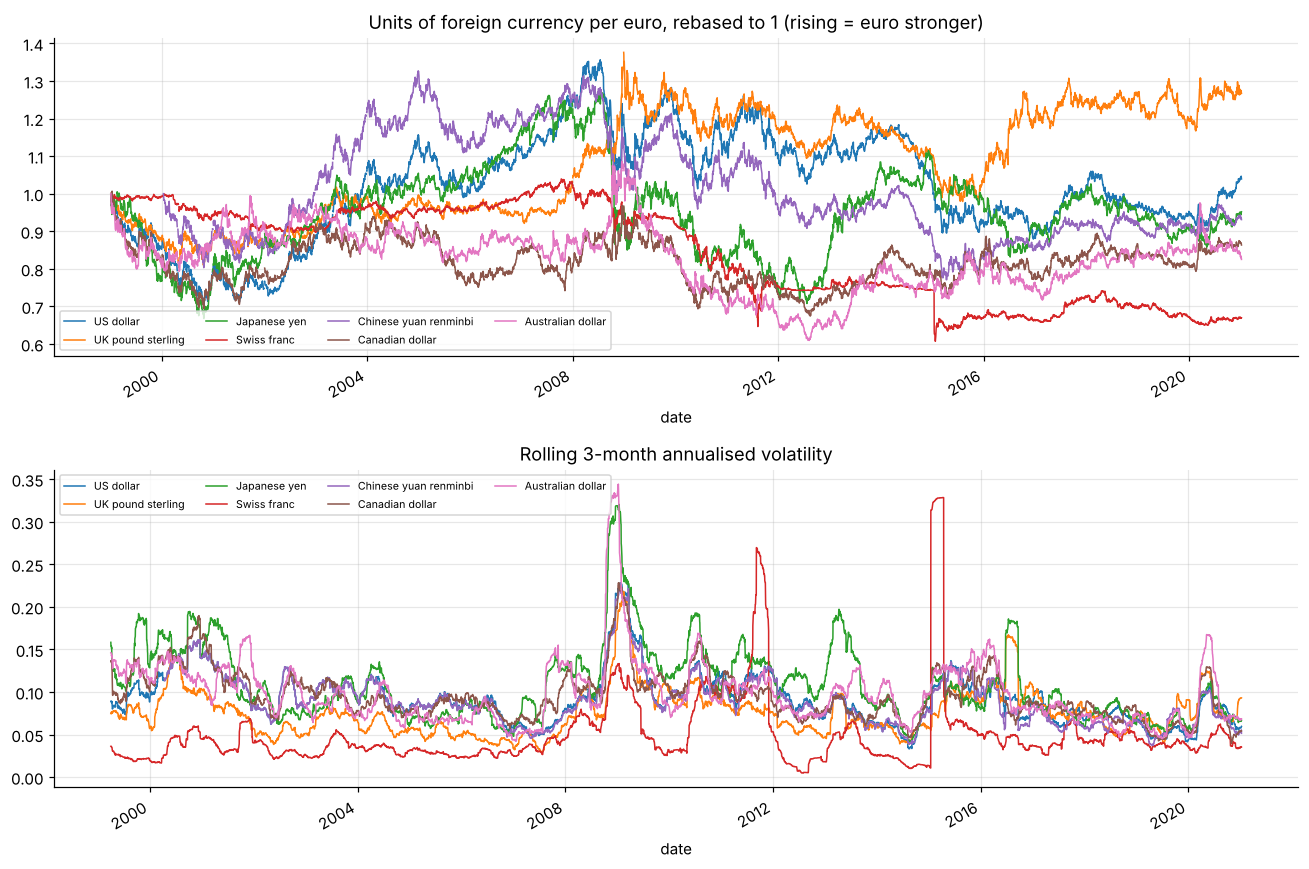

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(12, 8))
(fx[majors] / fx[majors].bfill().iloc[0]).plot(ax=ax[0], lw=1); ax[0].set_title("Units of foreign currency per euro, rebased to 1 (rising = euro stronger)")
(r.rolling(63).std() * np.sqrt(255)).plot(ax=ax[1], lw=1); ax[1].set_title("Rolling 3-month annualised volatility")
for a in ax: a.legend(fontsize=7, ncol=4)
fig.tight_layout(); plt.savefig(IMG / "fx_levels_vol.png", bbox_inches="tight"); plt.show()

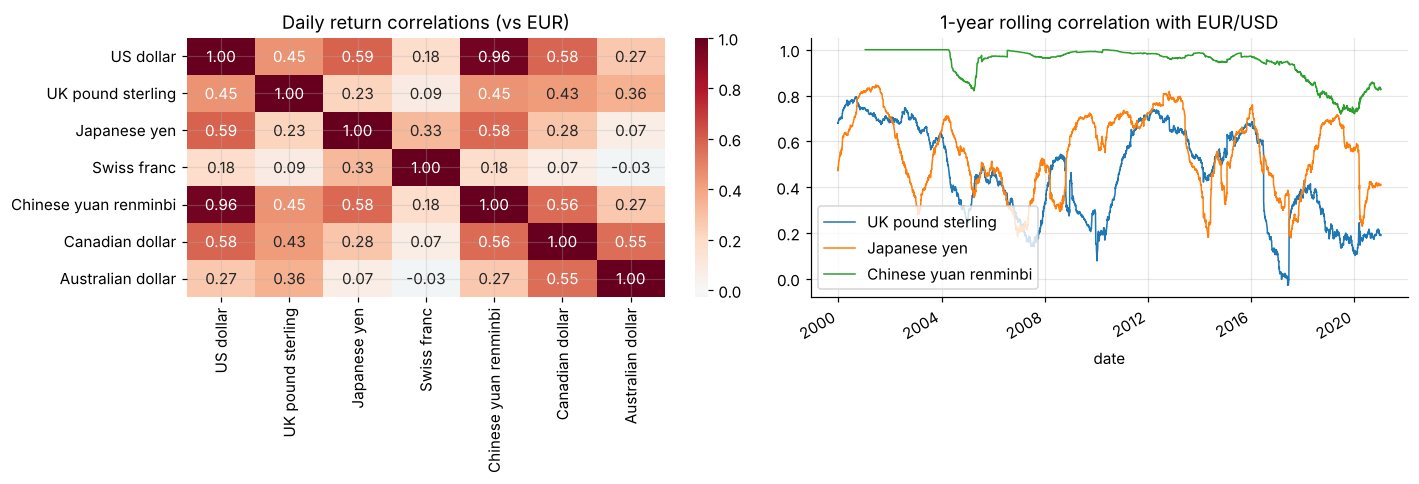

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(r.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax[0]); ax[0].set_title("Daily return correlations (vs EUR)")
usd = r["US dollar"].dropna()
roll = r.rolling(252).corr(usd).drop(columns="US dollar")
roll[["UK pound sterling", "Japanese yen", "Chinese yuan renminbi"]].plot(ax=ax[1], lw=1); ax[1].set_title("1-year rolling correlation with EUR/USD")
fig.tight_layout(); plt.savefig(IMG / "fx_correlation.png", bbox_inches="tight"); plt.show()

## Value-at-Risk of a receivables book
A euro-based company holds receivables of USD 4m, GBP 2m, JPY 300m and CNY 15m. What could it lose in euros over 10 days?

In [4]:
expo_fc = pd.Series({"US dollar": 4e6, "UK pound sterling": 2e6, "Japanese yen": 300e6, "Chinese yuan renminbi": 15e6})
last = fx[expo_fc.index].ffill().iloc[-1]
expo_eur = expo_fc / last                                 # EUR value today
rr = r[expo_fc.index].dropna()
pnl_hist = (-(rr) @ expo_eur)                             # foreign currency weakens vs EUR when the rate rises
pnl10 = pnl_hist.rolling(10).sum().dropna()
w250 = rr.iloc[-500:]
hs10 = (-(w250) @ expo_eur).rolling(10).sum().dropna()
cov = rr.iloc[-500:].cov() * 10
param = 2.326 * np.sqrt(expo_eur @ cov @ expo_eur)
tbl = pd.DataFrame({"EUR value": expo_eur.round(0)}); tbl.loc["Total"] = expo_eur.sum()
print(tbl.map(lambda v: f"€{v:,.0f}").to_string())
print(f"\n10-day 99% VaR, parametric (last 2y):        €{param:,.0f}  ({param / expo_eur.sum():.1%} of book)")
print(f"10-day 99% VaR, historical (last 2y):        €{-np.quantile(hs10, 0.01):,.0f}")
print(f"Worst 10-day loss since 1999 (stress):       €{-pnl10.min():,.0f} around {pnl10.idxmin():%b %Y}")
print(f"Diversification benefit vs sum of stand-alone VaRs: {1 - param / (2.326 * np.sqrt(np.diag(cov)) * expo_eur).sum():.0%}")

                        EUR value
US dollar              €3,265,306
UK pound sterling      €2,219,066
Japanese yen           €2,357,379
Chinese yuan renminbi  €1,894,322
Total                  €9,736,073

10-day 99% VaR, parametric (last 2y):        €227,554  (2.3% of book)
10-day 99% VaR, historical (last 2y):        €275,058
Worst 10-day loss since 1999 (stress):       €1,191,626 around Dec 2008
Diversification benefit vs sum of stand-alone VaRs: 29%


**Takeaways:** FX volatility comes in regimes and jumps. The Swiss franc moved 15.6% in a single day when the Swiss National Bank abandoned its euro floor on 15 January 2015, hence its extreme kurtosis. For this receivables book, the 10-day 99% VaR on the last two years is about €0.23-0.28m (≈ 2-3% of the book), but the worst 10-day loss since 1999 (December 2008) was about **€1.2m**, four to five times larger. VaR estimated on calm years understates stress losses, so the historical worst case should be reported alongside it. Correlation between currencies gives a real diversification benefit, but it is unstable, and hedging policy should be based on stressed rather than average correlations.